IMPORTAÇÃO DE BIBLIOTECAS

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from scipy import stats
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from pathlib import Path
from math import radians, cos, sin, asin, sqrt
from matplotlib.backends.backend_pdf import PdfPages

sns.set_theme(style='whitegrid')

DADOS

In [2]:
mobility_archives = Path(r"/home/lucas/Documentos/resenhadosdados/data/mobility_data").glob("*.csv")
meteorological_archive = r"/home/lucas/Documentos/resenhadosdados/data/auxiliar_data/meteorological_data.csv"

LEITURA DOS DADOS

In [3]:
#tabela de viagens
dfs = [pd.read_csv(archive) for archive in mobility_archives]
mobility_df = pd.concat(dfs, ignore_index=True)

#corrigindo valores salvos de maneira diferente no lineId
def convert_str_to_int(value):
    str_value = str(value)

    if str_value.replace('.', '').isdigit():
        num = float(str_value)
        if num.is_integer():
            return str(int(num))
        return str_value
    else:
        return str_value

mobility_df['lineId'] = mobility_df['lineId'].apply(convert_str_to_int)

#arrumando para datetime
mobility_df['timestamp'] = pd.to_datetime(mobility_df['timestamp'])

/tmp/ipykernel_26320/2782302.py:2: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  dfs = [pd.read_csv(archive) for archive in mobility_archives]


In [4]:
#mobility_df[mobility_df['lineId'] == '3']

In [5]:
#tabela completa meteorologica
meteorological_df = pd.read_csv(meteorological_archive) 
meteorological_df['Timestamp (UTC)'] = pd.to_datetime(meteorological_df['Timestamp (UTC)'])

meteorological_df.rename(columns={'Timestamp (UTC)': 'timestamp'}, inplace=True)

In [6]:
#rain_trip_df[rain_trip_df['lineId'] == '15']

GRÁFICOS DE CLIMA

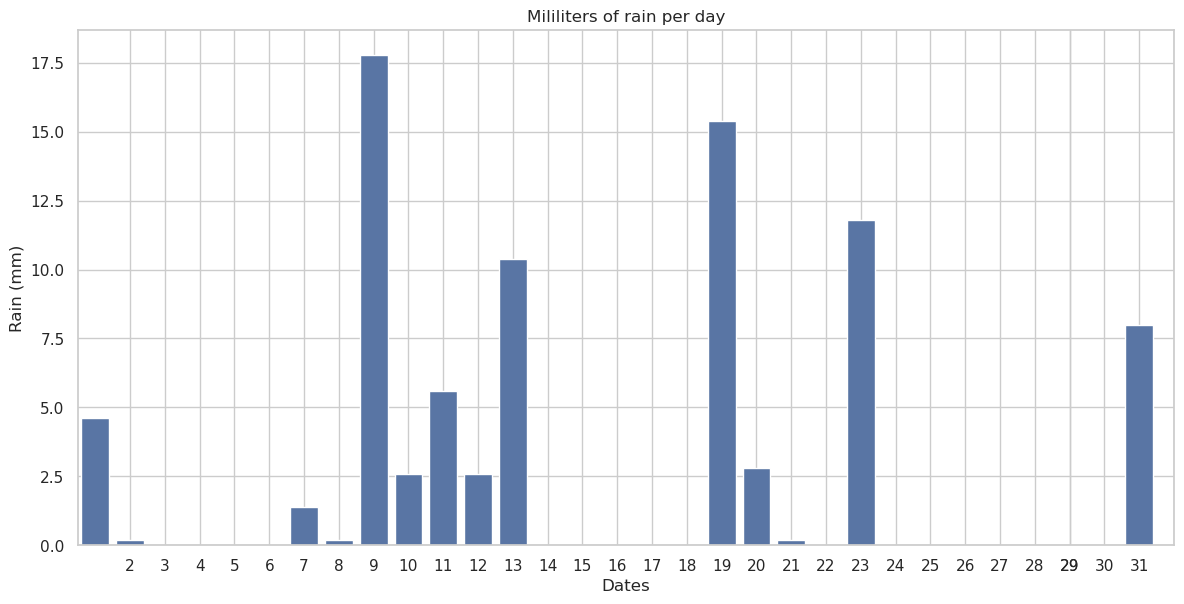

In [7]:
rain = meteorological_df.groupby([meteorological_df['timestamp'].dt.date])['Rain (mm)'].sum().reset_index()
rain['timestamp'] = pd.to_datetime(rain['timestamp'])

plt.figure(figsize=(12, 6))
sns.barplot(x=rain['timestamp'].dt.day, y=rain['Rain (mm)'], color='b')

plt.subplots_adjust(bottom=0.2) 
plt.xticks(rain['timestamp'].dt.day)
plt.tight_layout()
plt.title("Mililiters of rain per day")
plt.xlabel("Dates")
plt.ylabel("Rain (mm)")
plt.grid(True)
plt.show()


GRÁFICO DE VIAGENS


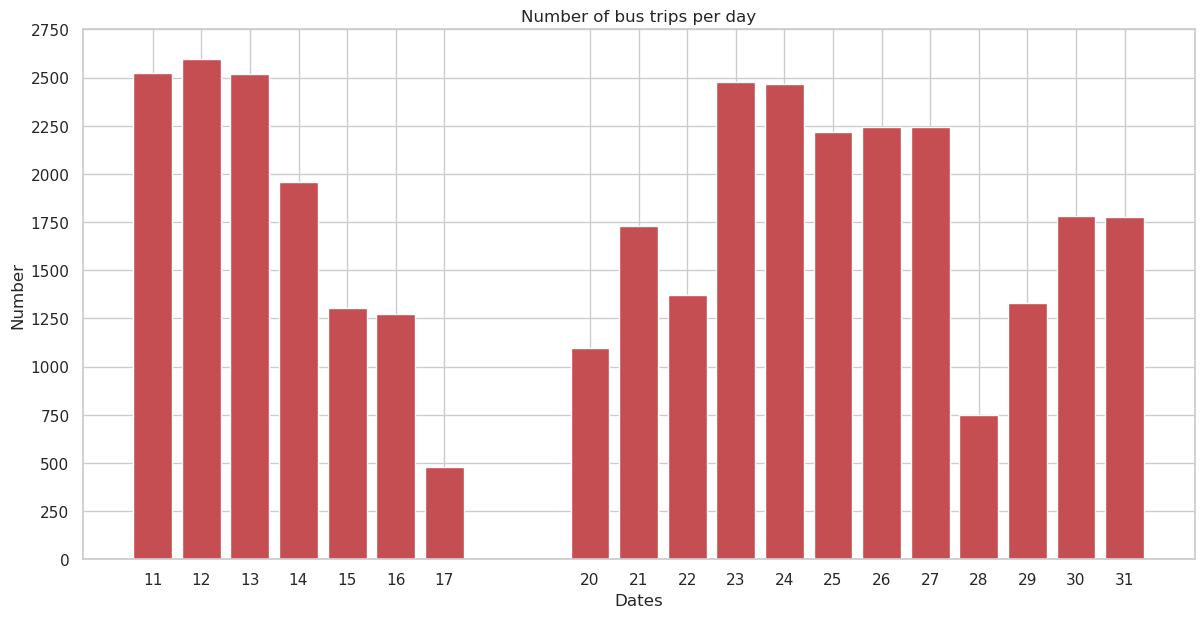

In [8]:
trips = mobility_df.groupby(pd.to_datetime(mobility_df['timestamp'].dt.date))['tripId'].nunique()

plt.figure(figsize=(12, 6))
plt.bar(x=trips.index.day, height=trips, color='r')

y_ticks = np.arange(0, max(trips) + 250, 250)
plt.yticks(y_ticks)

plt.subplots_adjust(bottom=0.2) 
plt.xticks(trips.index.day)
plt.tight_layout()
plt.title("Number of bus trips per day")
plt.xlabel("Dates")
plt.ylabel("Number")
plt.grid(True)
plt.show()

In [9]:
print("TripIds únicos:", mobility_df['tripId'].nunique())

print(
    "Combinações tripId + ônibus + sentido:",
    mobility_df.groupby(['tripId', 'id', 'heading']).ngroups
)

TripIds únicos: 7675
Combinações tripId + ônibus + sentido: 3395261


In [10]:
total = trips.sum()
print(total)

34144


['Circular / Campus da UFF' 'Circular / Campus da UFF'
 'Circular / Campus da UFF' ... 'Circular / Campus da UFF'
 'Circular / Campus da UFF' 'Circular / Campus da UFF']


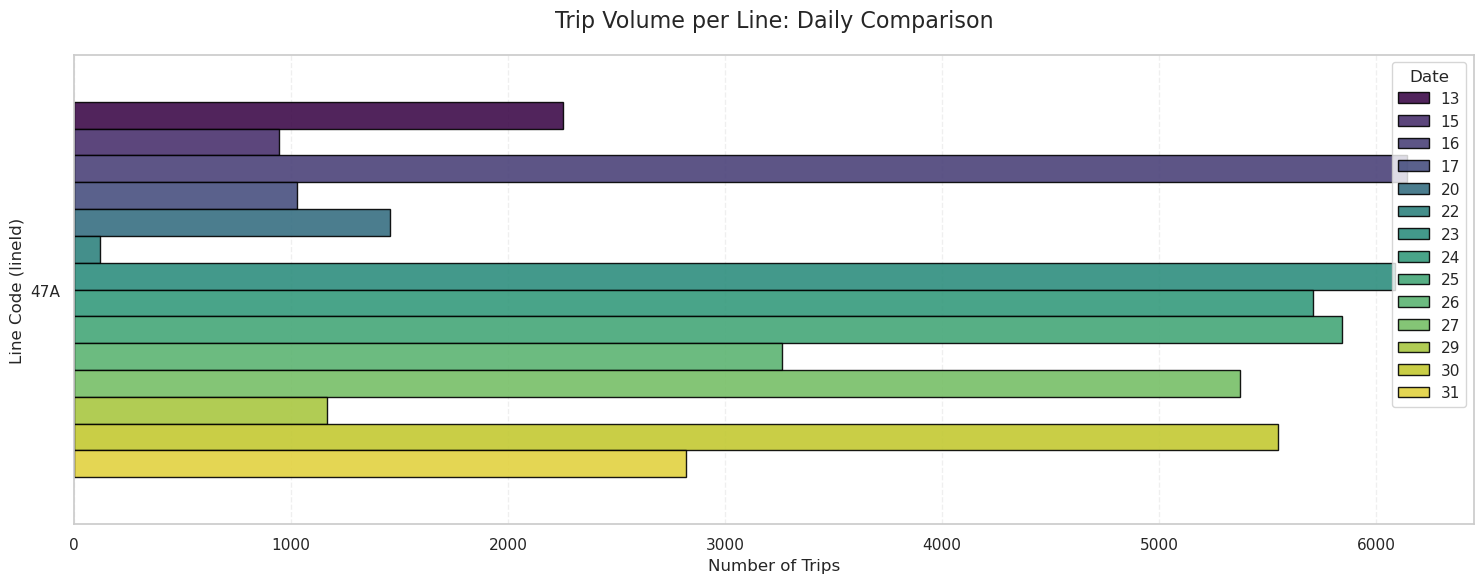

In [11]:
# Count trips per line and per day
mobility_df['date'] = mobility_df['timestamp'].dt.day
line_day_counts = mobility_df.groupby(['lineId', 'date']).size().reset_index(name='trip_count')

#especificando linha
lineId = '47A'
line_day_filtered = line_day_counts[line_day_counts['lineId'] == lineId]

name = mobility_df[mobility_df['lineId'] == lineId]['lineName'].values
print(name)

# Visualization
plt.figure(figsize=(15, 6))

# We use 'linha' on Y and 'trip_count' on X, with 'date' as the hue
sns.barplot(
    data=line_day_filtered,
    x='trip_count',
    y='lineId',
    hue='date',
    palette='viridis',
    edgecolor='black',
    legend='full',
    alpha=0.9
)

# 4. Formatting
plt.title('Trip Volume per Line: Daily Comparison', fontsize=16, pad=20)
plt.xlabel('Number of Trips', fontsize=12)
plt.ylabel('Line Code (lineId)', fontsize=12)
plt.legend(title='Date')
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

TEMPO MÉDIO, MIN E MÁXIMO DE CADA LINHA

In [12]:
#função que calcula a distancia entre dois pontos na superficie da terra
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1 
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    return 2 * asin(sqrt(a)) * 6371

mobility_df = mobility_df.sort_values(['tripId', 'timestamp'])

trip_stats = mobility_df.groupby(['tripId', 'date', 'id', 'direction']).agg(
    lineId=('lineId', 'first'),
    lineName=('lineName', 'unique'),
    min_time=('timestamp', 'min'),
    max_time=('timestamp', 'max'),
    start_lat=('lat', 'first'),
    start_lng=('lng', 'first'),
    end_lat=('lat', 'last'),
    end_lng=('lng', 'last')
).reset_index()

trip_stats['duration_min'] = (trip_stats['max_time'] - trip_stats['min_time']).dt.total_seconds() / 60.0
trip_stats['dist_km'] = trip_stats.apply(lambda x: haversine(x.start_lng, x.start_lat, x.end_lng, x.end_lat), axis=1)

trip_stats = trip_stats[(trip_stats['duration_min'] > 5) & (trip_stats['dist_km'] > 0.5)]

trip_stats = trip_stats[trip_stats["duration_min"] < 300]

trip_stats['avg_velocity'] = trip_stats['dist_km']/(trip_stats['duration_min'] / 60)

trip_stats = trip_stats[(trip_stats['avg_velocity'] >= 2) & (trip_stats['avg_velocity'] <= 80)]


print(f"Successfully characterized {len(trip_stats)} trips.")

Successfully characterized 50032 trips.


In [13]:
df_aux = trip_stats[trip_stats['lineId'] == 'OC3A']
df_aux = df_aux.sort_values(by='avg_velocity')
display(df_aux)

,tripId,date,id,direction,lineId,lineName,min_time,max_time,start_lat,start_lng,end_lat,end_lng,duration_min,dist_km,avg_velocity
6674,1257564_S_3,22,72746,0,OC3A,[OCEÂNICA 3A],2026-03-22 01:50:43,2026-03-22 04:05:24,-22.960320,-43.029930,-22.916756,-43.001518,134.683333,5.650654,2.517307
28999,1413905_U_3,13,72742,0,OC3A,[OCEÂNICA 3A],2026-03-13 02:13:44,2026-03-13 04:28:51,-22.967154,-43.039665,-22.920940,-43.005283,135.116667,6.229024,2.766065
6672,1257564_S_3,15,72744,0,OC3A,[OCEÂNICA 3A],2026-03-15 01:48:00,2026-03-15 04:08:53,-22.966307,-43.037361,-22.916412,-43.000748,140.883333,6.696034,2.851736
29001,1413905_U_3,14,72747,0,OC3A,[OCEÂNICA 3A],2026-03-14 02:13:59,2026-03-14 04:32:52,-22.968601,-43.042049,-22.916412,-43.000748,138.883333,7.180739,3.102203
28995,1413905_U_3,11,72742,0,OC3A,[OCEÂNICA 3A],2026-03-11 02:13:44,2026-03-11 04:31:22,-22.967154,-43.039665,-22.910646,-42.986332,137.633333,8.325084,3.629245
28998,1413905_U_3,12,72748,1,OC3A,[OCEÂNICA 3A],2026-03-12 03:24:33,2026-03-12 06:03:57,-22.890488,-43.124935,-22.913055,-42.986305,159.400000,14.419864,5.427803
16694,1350109_D_2,30,72733,1,OC3A,[OCEÂNICA 3A],2026-03-30 01:12:30,2026-03-30 02:34:00,-22.890341,-43.124790,-22.963787,-43.031597,81.500000,12.561240,9.247538
29009,1413905_U_5,12,72732,1,OC3A,[OCEÂNICA 3A],2026-03-12 02:09:43,2026-03-12 03:27:48,-22.890488,-43.124935,-22.966307,-43.037361,78.083333,12.308907,9.458285
6676,1257564_S_4,15,72754,1,OC3A,[OCEÂNICA 3A],2026-03-15 01:41:59,2026-03-15 02:58:19,-22.890488,-43.124935,-22.968840,-43.042080,76.333333,12.161487,9.559248
16705,1350109_D_5,16,83527,1,OC3A,[OCEÂNICA 3A],2026-03-16 04:14:32,2026-03-16 05:30:51,-22.890488,-43.124935,-22.935574,-43.010681,76.316667,12.730719,10.008864


In [14]:
'''
trips = (
    trip_stats
    .groupby(['date', 'id', 'direction'])['tripId']
    .nunique()
    .reset_index(name='trip_count')
)

plt.figure(figsize=(12, 6))
plt.bar(trips['date'], trips['trip_count'])

y_ticks = np.arange(0, trips['trip_count'].max() + 250, 250)
plt.yticks(y_ticks)

plt.subplots_adjust(bottom=0.2)
plt.tight_layout()

plt.title("Number of bus trips per day")
plt.xlabel("Date")
plt.ylabel("Number of trips")
plt.grid(True)

plt.show()
'''

'\ntrips = (\n    trip_stats\n    .groupby([\'date\', \'id\', \'direction\'])[\'tripId\']\n    .nunique()\n    .reset_index(name=\'trip_count\')\n)\n\nplt.figure(figsize=(12, 6))\nplt.bar(trips[\'date\'], trips[\'trip_count\'])\n\ny_ticks = np.arange(0, trips[\'trip_count\'].max() + 250, 250)\nplt.yticks(y_ticks)\n\nplt.subplots_adjust(bottom=0.2)\nplt.tight_layout()\n\nplt.title("Number of bus trips per day")\nplt.xlabel("Date")\nplt.ylabel("Number of trips")\nplt.grid(True)\n\nplt.show()\n'

In [15]:
line_stats = trip_stats.groupby(['lineId']).agg(
    shortest_time=('duration_min', 'min'),
    longest_time=('duration_min', 'max'),
    mean_time=('duration_min', 'mean'),
    shortest_dist=('dist_km', 'min'),
    longest_dist=('dist_km', 'max'),
    mean_dist=('dist_km', 'mean'),
    avg_velocity=('avg_velocity', 'mean'),
    shortest_vel=('avg_velocity', 'min'),
    fastest_vel=('avg_velocity', 'max'),
).reset_index()

line_stats = line_stats.round(3)
#limpando os tempos de viagens

In [16]:
line_stats[line_stats['lineId'] == 'OC3A']

,lineId,shortest_time,longest_time,mean_time,shortest_dist,longest_dist,mean_dist,avg_velocity,shortest_vel,fastest_vel
48,OC3A,10.267,159.4,68.426,1.863,14.42,11.647,11.324,2.517,17.125


In [17]:
'''
grupos = trip_stats['lineId'].unique()
n_colunas = 5
n_linhas = 10

fig, axes = plt.subplots(n_linhas, n_colunas, figsize=(20, 45))
axes = axes.flatten()

for i, grupo in enumerate(grupos):
    dados_grupo = trip_stats[trip_stats['lineId'] == grupo]['dist_km'].dropna()
    
    if len(dados_grupo) > 0:
        sns.boxplot(y=dados_grupo, ax=axes[i])
        axes[i].set_title(f'{grupo}\n(n={len(dados_grupo)})', fontsize=10)
    else:
        axes[i].text(0.5, 0.5, 'Sem dados', ha='center', va='center')
    
    axes[i].set_ylabel('Distancia percorrida (km)')

# Ocultar eixos extras (se houver menos de 50)
for j in range(len(grupos), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplots para 50 Grupos', fontsize=14)
plt.tight_layout()
plt.show()
'''

"\ngrupos = trip_stats['lineId'].unique()\nn_colunas = 5\nn_linhas = 10\n\nfig, axes = plt.subplots(n_linhas, n_colunas, figsize=(20, 45))\naxes = axes.flatten()\n\nfor i, grupo in enumerate(grupos):\n    dados_grupo = trip_stats[trip_stats['lineId'] == grupo]['dist_km'].dropna()\n    \n    if len(dados_grupo) > 0:\n        sns.boxplot(y=dados_grupo, ax=axes[i])\n        axes[i].set_title(f'{grupo}\n(n={len(dados_grupo)})', fontsize=10)\n    else:\n        axes[i].text(0.5, 0.5, 'Sem dados', ha='center', va='center')\n    \n    axes[i].set_ylabel('Distancia percorrida (km)')\n\n# Ocultar eixos extras (se houver menos de 50)\nfor j in range(len(grupos), len(axes)):\n    axes[j].set_visible(False)\n\nplt.suptitle('Boxplots para 50 Grupos', fontsize=14)\nplt.tight_layout()\nplt.show()\n"

JUNÇÃO VIAGENS E CHUVA

In [18]:
#merge das tabelas de viagem e chuva

#criamos a tabela rain_trip_df para juntar as infomações de chuva com as saidas dos ônibus
rain_df = meteorological_df.groupby([meteorological_df['timestamp'].dt.date])['Rain (mm)'].sum().reset_index()
rain_df['timestamp'] = pd.to_datetime(rain_df['timestamp'])
rain_df = meteorological_df[['timestamp','Rain (mm)']].copy()

rain_df['date'] = rain_df['timestamp'].dt.date
rain_df['hour'] = rain_df['timestamp'].dt.hour

trip_stats['date'] = trip_stats['min_time'].dt.date
trip_stats['hour'] = trip_stats['min_time'].dt.hour

rain_trip_df = pd.merge(rain_df, trip_stats, on=['date','hour'], how='right')

rain_trip_df = rain_trip_df.drop(columns=['date', 'hour'])

In [19]:
no_rain_trips = rain_trip_df[rain_trip_df['Rain (mm)'] < 2.5]["avg_velocity"]
rain_trips = rain_trip_df[rain_trip_df['Rain (mm)'] >= 2.5]["avg_velocity"]

#teste para media de tempo de viagem chuvoso vs nn chuvoso são iguais
t_stat, p_value_rain_trips = stats.ttest_ind(no_rain_trips, rain_trips, equal_var=False)
p_value_rain_trips

1.1402262582679391e-52

array([<AxesSubplot: title={'center': 'False'}>,
       <AxesSubplot: title={'center': 'True'}>], dtype=object)

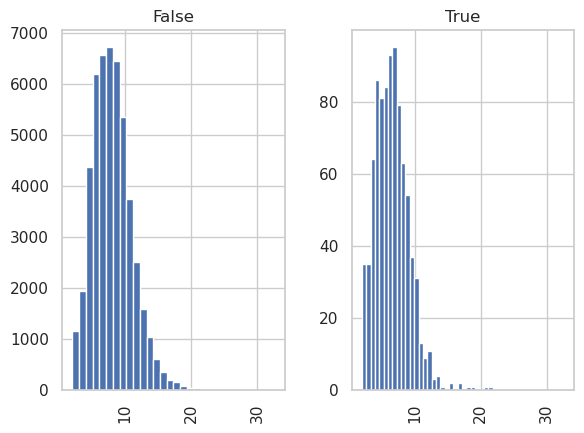

In [20]:
#gera histogramas com a distribuição da VELOCIDADE das viagens sem chuva vs com chuva
rain_trip_df['avg_velocity'].hist(by=rain_trip_df['Rain (mm)'] >= 2.5, bins=30,sharex=True)

array([<AxesSubplot: title={'center': 'False'}>,
       <AxesSubplot: title={'center': 'True'}>], dtype=object)

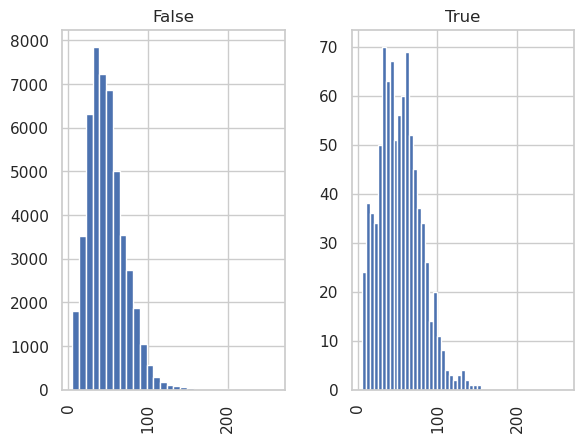

In [21]:
#gera histogramas com a distribuição da DURAÇÃO das viagens sem chuva vs com chuva
rain_trip_df['duration_min'].hist(by=rain_trip_df['Rain (mm)'] >= 2.5, bins=30,sharex=True)

In [22]:
stat, p_value = mannwhitneyu(no_rain_trips, rain_trips, alternative='two-sided')
print(f"P-valor (Mann-Whitney): {p_value}")

P-valor (Mann-Whitney): 3.3870521202087187e-50


TESTE DE INFLUENCIA DA CHUVA EM CADA LINHA

In [23]:
def calcular_cohen_d(g1, g2):
    # Médias
    m1, m2 = np.mean(g1), np.mean(g2)
    
    # Tamanhos das amostras
    n1, n2 = len(g1), len(g2)
    
    # Variâncias
    v1, v2 = np.var(g1, ddof=1), np.var(g2, ddof=1)
    
    # Desvio padrão agrupado (Pooled Standard Deviation)
    sd_pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
    
    # Retorna o d de Cohen
    return abs((m1 - m2) / sd_pooled)

In [24]:
#teste pela velocidade
from scipy.stats import mannwhitneyu

lines = rain_trip_df['lineId'].unique()
results = []

for line in lines:
    df_line = rain_trip_df[rain_trip_df['lineId'] == line]
    
    name = df_line["lineName"]
    no_rain = df_line[df_line["Rain (mm)"] < 2.5]["avg_velocity"]
    rain = df_line[df_line["Rain (mm)"] >= 2.5]["avg_velocity"]
    
    #determina numero de amostras para que o teste seja realizado
    if len(no_rain) > 5 and len(rain) > 5:
        stat, p_value = mannwhitneyu(no_rain, rain, alternative='two-sided')
        
        results.append({
            'lineId': line,
            'lineName': name,
            'p_value': p_value,
            'media_seco': no_rain.mean(),
            'media_chuva': rain.mean(),
            'diferenca_vel': rain.mean() - no_rain.mean(),
            'n_viagens_chuva': len(rain)
        })

df_results = pd.DataFrame(results)

# Filtrar o que é estatisticamente significativo (p < 0.05) e ordenar pelas linhas mais afetadas
df_affected = df_results[df_results['p_value'] < 0.05].sort_values(by='diferenca_vel', ascending=True).reset_index()

print(df_affected)

    index lineId                                           lineName  \
0      19    55A  3285     [VÁRZEA DAS MOÇAS X PIRATININGA]
3286...   
1      35     26  19856    [FLORÁRIA X CENTRO]
19857    [FLORÁRI...   
2       6    26A  686      [MORRO CÉU X CENTRO]
687      [MORRO ...   
3       0   41BC  7        [VENDA DA CRUZ X TERMINAL - VIA BENJA...   
4      33     40  9710     [MACEIÓ X CENTRO]
9711     [MACEIÓ X ...   
5      10    34A  1486     [LARGO DA BATALHA X CENTRO]
1487     ...   
6      13     53  2057     [SANTA ROSA X CENTRO]
2058     [SANTA...   
7      15     35  2389     [BALDEADOR X CENTRO]
2390     [BALDEA...   
8       5     22  608      [BONFIM X AMARAL PEIXOTO]
609      [B...   
9       1   41JB  106      [VENDA DA CRUZ X TERMINAL - VIA JOAO ...   
10      2    42T  216      [VENDA DA CRUZ X TERMINAL]
217      [...   
11     32     44  7994     [ITITIOCA X CENTRO]
7995     [ITITIOC...   
12     21     52  4276     [BALDEADOR X ITAIPU (VIA CANTAGALO)]
...   
13    

In [28]:
#teste pelo tempo
from scipy.stats import mannwhitneyu

lines = rain_trip_df['lineId'].unique()
results = []

for line in lines:
    df_line = rain_trip_df[rain_trip_df['lineId'] == line]
    
    name = df_line["lineName"]
    no_rain = df_line[df_line["Rain (mm)"] < 2.5]["duration_min"]
    rain = df_line[df_line["Rain (mm)"] >= 2.5]["duration_min"]
    
    #determina numero de amostras para que o teste seja realizado
    if len(no_rain) > 5 and len(rain) > 5:
        stat, p_value = mannwhitneyu(no_rain, rain, alternative='two-sided')
        
        results.append({
            'lineId': line,
            'lineName': name,
            'p_value': p_value,
            'cohen': calcular_cohen_d(no_rain, rain),
            'mediana_seco': no_rain.median(),
            'mediana_chuva': rain.median(),
            'diferenca_min': rain.median() - no_rain.median(),
            'n_viagens_chuva': len(rain)
        })

df_results = pd.DataFrame(results)

rejeicao, pvals_corrigidos, _, _ = multipletests(df_results["p_value"], alpha=0.05, method='bonferroni')

# Filtrar o que é estatisticamente significativo (p < 0.05) e ordenar pelas linhas mais afetadas
df_affected = df_results[rejeicao]


df_affected

,lineId,lineName,p_value,cohen,mediana_seco,mediana_chuva,diferenca_min,n_viagens_chuva
1,41JB,106 [VENDA DA CRUZ X TERMINAL - VIA JOAO ...,7.442469e-06,0.878321,33.766667,41.700000,7.933333,19
12,45,1759 [CUBANGO X CENTRO] 1760 [CUBANGO ...,8.005878e-04,0.409803,35.283333,44.825000,9.541667,78
14,OC1,2238 [OCEÂNICA 1] 2239 [OCEÂNICA 1] 22...,4.670055e-06,0.621535,60.300000,74.641667,14.341667,34
21,52,4276 [BALDEADOR X ITAIPU (VIA CANTAGALO)] ...,5.607929e-04,0.855542,71.808333,87.666667,15.858333,13
29,61,6587 [VENDA DA CRUZ X ICARAI] 6588 [VE...,1.595383e-10,1.153489,63.000000,79.441667,16.441667,30
32,44,7994 [ITITIOCA X CENTRO] 7995 [ITITIOC...,9.009987e-04,1.133076,43.800000,56.816667,13.016667,15


In [29]:
# 1. Define o tamanho da figura PRIMEIRO
plt.figure(figsize=(10, 6))

# Formata os nomes das linhas (mantendo o seu corte de caracteres)
df_affected["lineName"] = (
    df_affected["lineName"].astype(str)
)

for i in range(len(df_affected["lineName"])):
    s = df_affected["lineName"].iloc[i]
    k = 0
    while (k<len(s) and s[k]!="["):
        k = k + 1
        if (k>len(s)):
            break
    j = k
    while (j<len(s) and s[j]!="]"):
        j = j + 1
        if (j>len(s)):
                break
    df_affected["lineName"].iloc[i] = s[k+1:j]

/tmp/ipykernel_26320/823663208.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_affected["lineName"] = (
/tmp/ipykernel_26320/823663208.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_affected["lineName"].iloc[i] = s[k+1:j]
/tmp/ipykernel_26320/823663208.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_affected["lineName"].iloc[i] = s[k+1:j]
/tmp/ipykernel_26

<Figure size 1000x600 with 0 Axes>

In [30]:
df_affected["lineName"] = df_affected["lineName"].str.slice(stop=25) + "..."

/tmp/ipykernel_26320/672787430.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_affected["lineName"] = df_affected["lineName"].str.slice(stop=25) + "..."


/tmp/ipykernel_26320/2090226837.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_affected, y="lineName", x="diferenca_min", palette="Reds_r")


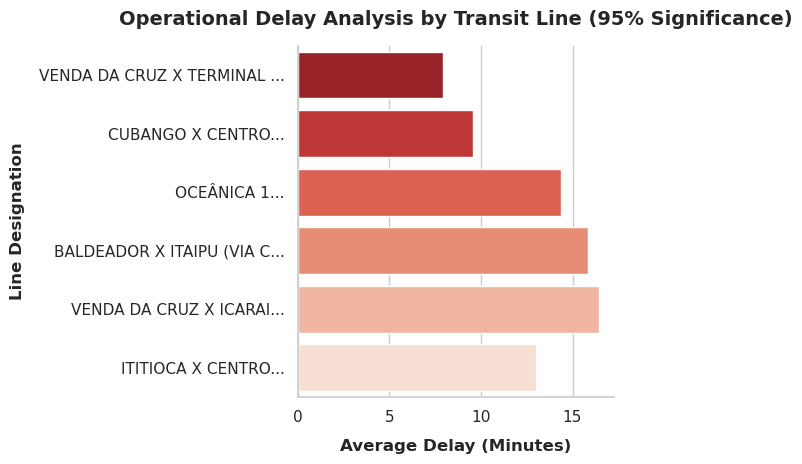

In [31]:
# 2. Cria o gráfico (adicionei uma paleta de cores mais sóbria/formal)
sns.barplot(data=df_affected, y="lineName", x="diferenca_min", palette="Reds_r")

# 3. Labels e Títulos Formais
# Nota: Se 'diferenca_min' for em minutos, use (min). Se já for em segundos, mude para (s).
plt.xlabel("Average Delay (Minutes)", fontsize=12, fontweight="bold", labelpad=10)
plt.ylabel("Line Designation", fontsize=12, fontweight="bold", labelpad=10)
plt.title(
    "Operational Delay Analysis by Transit Line (95% Significance)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

# 4. Toques finais de estilo (remove as bordas desnecessárias de cima e da direita)
sns.despine()
plt.tight_layout()

# 5. Exibe o gráfico já formatado
plt.savefig("delay_linha.pdf", bbox_inches='tight', format="pdf")
plt.show()

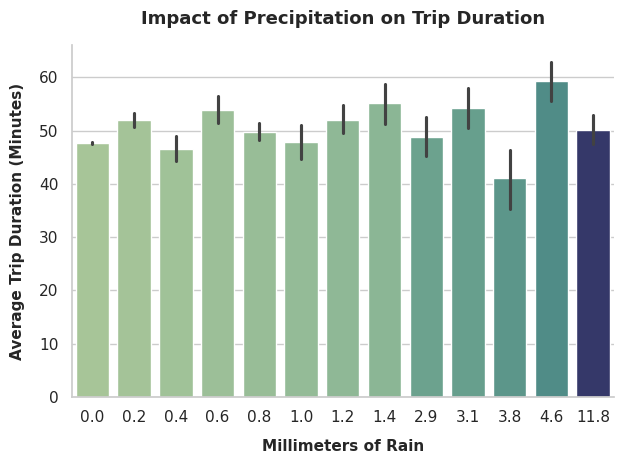

In [32]:
sns.barplot(data=rain_trip_df, x="Rain (mm)", y="duration_min", hue="Rain (mm)", palette="crest", legend=False)

plt.xlabel("Millimeters of Rain", fontsize=11, fontweight="bold", labelpad=10)
plt.ylabel("Average Trip Duration (Minutes)", fontsize=11, fontweight="bold", labelpad=10)
plt.title("Impact of Precipitation on Trip Duration", fontsize=13, fontweight="bold", pad=15)

sns.despine()

plt.tight_layout()
plt.savefig("chuva_duration.pdf", format="pdf")
plt.show()

/tmp/ipykernel_26320/3812560683.py:10: UserWarning: 
The palette list has fewer values (4) than needed (13) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(data=rain_trip_df, x="Rain (mm)", y="avg_velocity", hue="Rain (mm)", palette=custom_blues_inverted, legend=False)


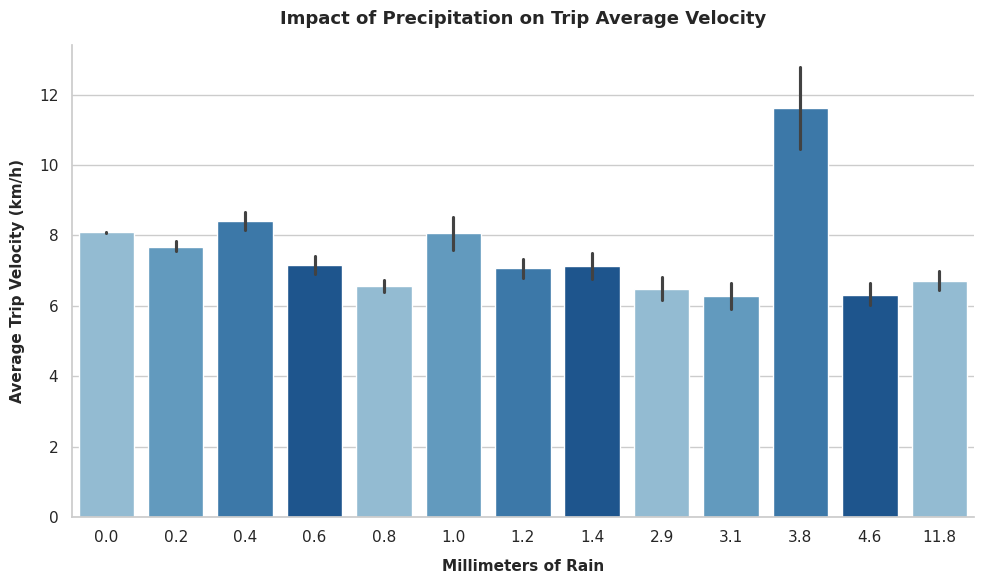

In [33]:
# 1. Cria 12 tons de azul
custom_blues_inverted = sns.color_palette("Blues")
# 2. Remove os 3 tons mais claros do final (evita o branco)
custom_blues_inverted = custom_blues_inverted[2:]

# 1. Garante um bom espaço para as barras e textos não se espremerem
plt.figure(figsize=(10, 6))

# 2. Cria o gráfico
sns.barplot(data=rain_trip_df, x="Rain (mm)", y="avg_velocity", hue="Rain (mm)", palette=custom_blues_inverted, legend=False)

# 3. Labels e Título
plt.xlabel("Millimeters of Rain", fontsize=11, fontweight="bold", labelpad=10)
plt.ylabel("Average Trip Velocity (km/h)", fontsize=11, fontweight="bold", labelpad=10)
plt.title("Impact of Precipitation on Trip Average Velocity", fontsize=13, fontweight="bold", pad=15)

# 4. Estética
sns.despine()
plt.tight_layout()

# 5. Exibe
plt.savefig("velocidade_linha.pdf", format="pdf")
plt.show()